# 04 · RFM Verification & K-Means Customer Segmentation

**Project:** Olist E-Commerce Customer Segmentation & Retention Analysis  
## Purpose
1. Independently recalculates RFM metrics in Python and cross-checks them against the SQL-generated table.
2. Prepares the features for clustering (log transformation, capping, standardisation).
3. Selects the number of clusters, trains a K-Means model, and profiles the resulting customer segments and their revenue contribution.

| | |
|---|---|
| **Input** | `customer_rfm_segments_clean.csv` (Notebook 02) · `olist_customers_dataset.csv` · `olist_orders_dataset.csv` · `order_items_no_header.csv` (Notebook 02) |
| **Output** | `olist_customer_segments.csv` (used by Notebook 05) · `customer_rfm_python_verified.csv` · 4 segment summary CSVs |
| **Libraries** | pandas, numpy, matplotlib, seaborn, scikit-learn |
| **Environment** | Google Colab |

> **How to run:** execute the cells in order and upload each requested file when prompted.

## 1. Setup

In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Load the SQL-Generated RFM Table

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving customer_rfm_segments_clean.csv to customer_rfm_segments_clean.csv


In [ ]:
# Load cleaned RFM dataset

file_name = "/content/customer_rfm_segments_clean.csv"

rfm_df = pd.read_csv(file_name)

print("First 5 rows:")
display(rfm_df.head())

print("\nDataset Shape:", rfm_df.shape)

print("\nColumns:")
print(rfm_df.columns.tolist())

First 5 rows:


,customer_unique_id,recency_days,frequency,monetary,R_score,F_score,M_score,RFM_score,RFM_total,customer_segment
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,129.90,4,1,2,412,7,Potential Loyalists
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,18.90,4,1,1,411,6,Potential Loyalists
2,0000f46a3911fa3c0805444483337064,537,1,69.00,2,1,1,211,4,Hibernating
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,3,1,1,311,5,Needs Nurturing
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,3,1,2,312,6,Needs Nurturing



Dataset Shape: (93358, 10)

Columns:
['customer_unique_id', 'recency_days', 'frequency', 'monetary', 'R_score', 'F_score', 'M_score', 'RFM_score', 'RFM_total', 'customer_segment']


In [ ]:
# Check data types
print("Data Types:")
print(rfm_df.dtypes)

# Check missing values
print("\nMissing Values:")
print(rfm_df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", rfm_df.duplicated().sum())

# Check duplicate customer IDs
print(
    "Duplicate Customer IDs:",
    rfm_df["customer_unique_id"].duplicated().sum()
)

# Check numerical summary
print("\nNumerical Summary:")
display(
    rfm_df[["recency_days", "frequency", "monetary"]].describe()
)

Data Types:
customer_unique_id     object
recency_days            int64
frequency               int64
monetary              float64
R_score                 int64
F_score                 int64
M_score                 int64
RFM_score               int64
RFM_total               int64
customer_segment       object
dtype: object

Missing Values:
customer_unique_id    0
recency_days          0
frequency             0
monetary              0
R_score               0
F_score               0
M_score               0
RFM_score             0
RFM_total             0
customer_segment      0
dtype: int64

Duplicate Rows: 0
Duplicate Customer IDs: 0

Numerical Summary:


,recency_days,frequency,monetary
count,93358.00,93358.00,93358.00
mean,237.48,1.03,141.62
std,152.60,0.21,215.69
min,0.00,1.00,0.85
25%,114.00,1.00,47.65
50%,218.00,1.00,89.73
75%,346.00,1.00,154.74
max,713.00,15.00,13440.00


## 3. Independent RFM Recalculation in Python
The RFM metrics are rebuilt from the raw tables and compared with the SQL output.

### 3.1 Upload the raw tables

In [ ]:
from google.colab import files

uploaded_files = files.upload()

print("\nUploaded files:")
for filename in uploaded_files.keys():
    print(filename)

Saving olist_customers_dataset.csv to olist_customers_dataset.csv

Uploaded files:
olist_customers_dataset.csv


In [ ]:
from google.colab import files

uploaded_files = files.upload()

print("\nUploaded files:")
for filename in uploaded_files.keys():
    print(filename)

Saving olist_orders_dataset.csv to olist_orders_dataset.csv

Uploaded files:
olist_orders_dataset.csv


In [ ]:
from google.colab import files

uploaded_files = files.upload()

print("\nUploaded files:")
for filename in uploaded_files.keys():
    print(filename)

Saving order_items_no_header.csv to order_items_no_header.csv

Uploaded files:
order_items_no_header.csv


### 3.2 Load and inspect
Customers and orders have header rows; the order-items file was exported without headers (Notebook 02), so column names are supplied manually.

In [ ]:
# Load customers and orders normally (they have headers)

customers_df = pd.read_csv(
    "/content/olist_customers_dataset.csv"
)

orders_df = pd.read_csv(
    "/content/olist_orders_dataset.csv"
)

# Load order items without headers (using the uploaded file 'order_items_no_header.csv')

item_columns = [
    "order_id",
    "order_item_id",
    "product_id",
    "seller_id",
    "shipping_limit_date",
    "price",
    "freight_value"
]

order_items_df = pd.read_csv(
    "/content/order_items_no_header.csv",
    header=None,
    names=item_columns
)

print("Customers:", customers_df.shape)
print("Orders:", orders_df.shape)
print("Order Items:", order_items_df.shape)

Customers: (99441, 5)
Orders: (99441, 8)
Order Items: (112650, 7)


In [ ]:
# Verify order items dataset

print("Columns:")
print(order_items_df.columns.tolist())

print("\nFirst 5 rows:")
display(order_items_df.head())

print("\nData Types:")
print(order_items_df.dtypes)

Columns:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

First 5 rows:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14



Data Types:
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64
dtype: object


In [ ]:
print("CUSTOMERS")
print(customers_df[["customer_id", "customer_unique_id"]].dtypes)

print("\nORDERS")
print(orders_df[[
    "order_id",
    "customer_id",
    "order_status",
    "order_purchase_timestamp"
]].dtypes)

print("\nORDER ITEMS")
print(order_items_df[[
    "order_id",
    "price"
]].dtypes)

CUSTOMERS
customer_id           object
customer_unique_id    object
dtype: object

ORDERS
order_id                    object
customer_id                 object
order_status                object
order_purchase_timestamp    object
dtype: object

ORDER ITEMS
order_id     object
price       float64
dtype: object


In [ ]:
# Convert date columns to datetime

orders_df["order_purchase_timestamp"] = pd.to_datetime(
    orders_df["order_purchase_timestamp"],
    errors="coerce"
)

order_items_df["shipping_limit_date"] = pd.to_datetime(
    order_items_df["shipping_limit_date"],
    errors="coerce"
)

# Verify conversions

print("Order purchase timestamp:")
print(orders_df["order_purchase_timestamp"].dtype)

print("\nShipping limit date:")
print(order_items_df["shipping_limit_date"].dtype)

print("\nMissing purchase timestamps:",
      orders_df["order_purchase_timestamp"].isna().sum())

print("Missing shipping dates:",
      order_items_df["shipping_limit_date"].isna().sum())

Order purchase timestamp:
datetime64[ns]

Shipping limit date:
datetime64[ns]

Missing purchase timestamps: 0
Missing shipping dates: 0


### 3.3 Delivered orders and customer revenue
Only **delivered** orders are used. Orders are joined to customers (to obtain the unique customer ID) and to order items (to obtain product price).

In [ ]:
# Filter only delivered orders

delivered_orders_df = orders_df[
    orders_df["order_status"] == "delivered"
].copy()

print("Total orders:", len(orders_df))
print("Delivered orders:", len(delivered_orders_df))

print("\nDelivered order date range:")
print("Earliest:", delivered_orders_df["order_purchase_timestamp"].min())
print("Latest:", delivered_orders_df["order_purchase_timestamp"].max())

print("\nMissing order IDs:",
      delivered_orders_df["order_id"].isna().sum())

Total orders: 99441
Delivered orders: 96478

Delivered order date range:
Earliest: 2016-09-15 12:16:38
Latest: 2018-08-29 15:00:37

Missing order IDs: 0


In [ ]:
# Merge delivered orders with customer information

customer_orders_df = delivered_orders_df.merge(
    customers_df[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="inner"
)

print("Merged dataset shape:", customer_orders_df.shape)

print("\nUnique customers:",
      customer_orders_df["customer_unique_id"].nunique())

print("Unique orders:",
      customer_orders_df["order_id"].nunique())

print("\nDuplicate order IDs:",
      customer_orders_df["order_id"].duplicated().sum())

Merged dataset shape: (96478, 9)

Unique customers: 93358
Unique orders: 96478

Duplicate order IDs: 0


In [ ]:
# Merge delivered customer orders with order items

customer_items_df = customer_orders_df.merge(
    order_items_df[["order_id", "price"]],
    on="order_id",
    how="inner"
)

print("Merged dataset shape:", customer_items_df.shape)

print("\nUnique orders:",
      customer_items_df["order_id"].nunique())

print("Unique customers:",
      customer_items_df["customer_unique_id"].nunique())

print("\nTotal item revenue:",
      round(customer_items_df["price"].sum(), 2))

print("\nMissing prices:",
      customer_items_df["price"].isna().sum())

Merged dataset shape: (110197, 10)

Unique orders: 96478
Unique customers: 93358

Total item revenue: 13221498.11

Missing prices: 0


### 3.4 Calculate recency, frequency and monetary value
The reference date is the latest delivered purchase date in the data.

In [ ]:
# Reference date: latest delivered purchase date
reference_date = delivered_orders_df[
    "order_purchase_timestamp"
].max()

# Calculate RFM metrics for each customer
rfm_python = customer_items_df.groupby(
    "customer_unique_id"
).agg(
    recency=(
        "order_purchase_timestamp",
        lambda x: (reference_date - x.max()).days
    ),
    frequency=("order_id", "nunique"),
    monetary=("price", "sum")
).reset_index()

# Round monetary values
rfm_python["monetary"] = rfm_python["monetary"].round(2)

# Display results
print("RFM dataset shape:", rfm_python.shape)

print("\nRFM Summary:")
display(rfm_python[[
    "recency", "frequency", "monetary"
]].describe().round(2))

print("\nFirst 5 customers:")
display(rfm_python.head())

RFM dataset shape: (93358, 4)

RFM Summary:


,recency,frequency,monetary
count,93358.00,93358.00,93358.00
mean,236.94,1.03,141.62
std,152.59,0.21,215.69
min,0.00,1.00,0.85
25%,113.00,1.00,47.65
50%,218.00,1.00,89.73
75%,345.00,1.00,154.74
max,713.00,15.00,13440.00



First 5 customers:


,customer_unique_id,recency,frequency,monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,18.90
2,0000f46a3911fa3c0805444483337064,536,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,320,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,287,1,180.00


In [ ]:
# Recalculate recency using calendar dates, like MySQL DATEDIFF()

reference_date = delivered_orders_df[
    "order_purchase_timestamp"
].max().normalize()

rfm_python["recency"] = customer_items_df.groupby(
    "customer_unique_id"
)["order_purchase_timestamp"].max().apply(
    lambda date: (reference_date - date.normalize()).days
).values

print("Updated RFM Summary:")
display(
    rfm_python[["recency", "frequency", "monetary"]]
    .describe()
    .round(2)
)

Updated RFM Summary:


,recency,frequency,monetary
count,93358.00,93358.00,93358.00
mean,237.48,1.03,141.62
std,152.60,0.21,215.69
min,0.00,1.00,0.85
25%,114.00,1.00,47.65
50%,218.00,1.00,89.73
75%,346.00,1.00,154.74
max,713.00,15.00,13440.00


### 3.5 Compare with the SQL result

In [ ]:
# Select and rename SQL RFM columns
rfm_sql = rfm_df[
    ["customer_unique_id", "recency_days", "frequency", "monetary"]
].copy()

rfm_sql = rfm_sql.rename(columns={
    "recency_days": "recency"
})

# Sort both datasets by customer ID
rfm_python_sorted = rfm_python.sort_values(
    "customer_unique_id"
).reset_index(drop=True)

rfm_sql_sorted = rfm_sql.sort_values(
    "customer_unique_id"
).reset_index(drop=True)

# Compare customer IDs
print("Customer IDs match:",
      rfm_python_sorted["customer_unique_id"].equals(
          rfm_sql_sorted["customer_unique_id"]
      ))

# Compare RFM values
for column in ["recency", "frequency", "monetary"]:
    differences = (
        rfm_python_sorted[column] != rfm_sql_sorted[column]
    ).sum()

    print(f"{column} mismatches:", differences)

Customer IDs match: True
recency mismatches: 0
frequency mismatches: 0
monetary mismatches: 0


#### Findings: Python vs SQL
- Delivered orders: 96,478 of 99,441 (purchase dates from 2016-09-15 to 2018-08-29), belonging to **93,358 unique customers**. Total product revenue is R$13,221,498.11 (freight excluded).
- A first attempt using exact timestamps produced a slightly different mean recency (236.94 vs 237.48 days). After computing recency from **calendar-day differences** (the equivalent of MySQL's `DATEDIFF()`), Python and SQL agree on all customers.
- Result: **0 mismatches** in recency, frequency and monetary value across all 93,358 customers.

### 3.6 Save the verified RFM table

In [ ]:
# Save independently calculated RFM data

rfm_python.to_csv(
    "customer_rfm_python_verified.csv",
    index=False
)

print("File saved successfully!")
print("Shape:", rfm_python.shape)

File saved successfully!
Shape: (93358, 4)


## 4. Feature Engineering for Clustering
K-Means uses distances, so highly skewed features must be transformed and all features put on the same scale.

Skewness of RFM Features:

recency: 0.45
frequency: 11.10
monetary: 9.75


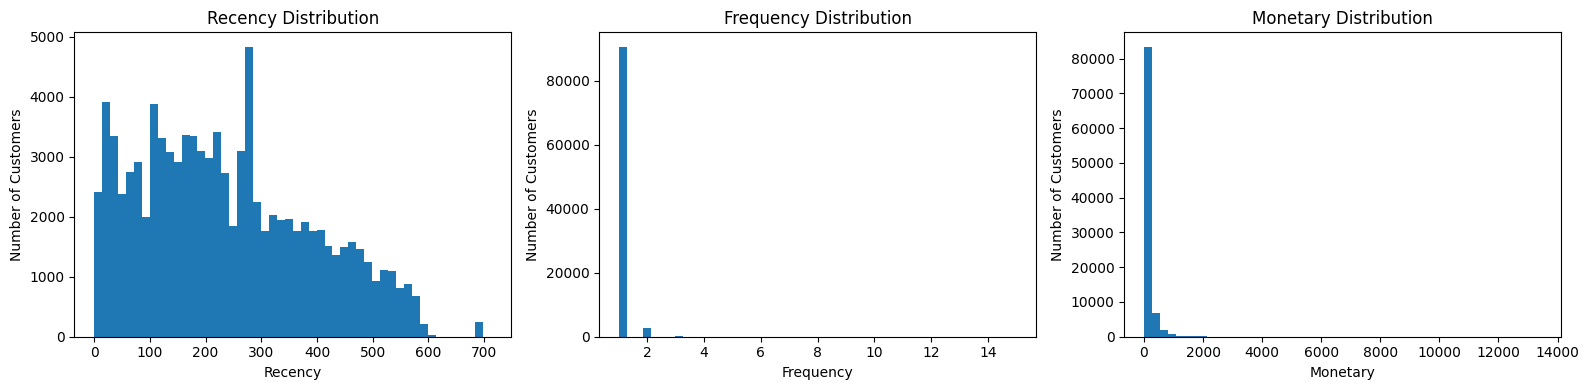

In [ ]:
rfm_features = ["recency", "frequency", "monetary"]

print("Skewness of RFM Features:\n")

for column in rfm_features:
    print(f"{column}: {rfm_python[column].skew():.2f}")

# Visualize distributions
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, column in enumerate(rfm_features):
    axes[i].hist(rfm_python[column], bins=50)
    axes[i].set_title(f"{column.capitalize()} Distribution")
    axes[i].set_xlabel(column.capitalize())
    axes[i].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# Create a copy for clustering preparation
rfm_model = rfm_python[
    ["customer_unique_id", "recency", "frequency", "monetary"]
].copy()

# Apply log transformation
rfm_model["frequency_log"] = np.log1p(
    rfm_model["frequency"]
)

rfm_model["monetary_log"] = np.log1p(
    rfm_model["monetary"]
)

# Check transformed distributions
print("Skewness after Log Transformation:\n")

print("Frequency:", round(rfm_model["frequency_log"].skew(), 2))
print("Monetary:", round(rfm_model["monetary_log"].skew(), 2))

Skewness after Log Transformation:

Frequency: 6.52
Monetary: 0.28


In [ ]:
# Select features for K-Means
clustering_features = [
    "recency",
    "frequency_log",
    "monetary_log"
]

# Check feature statistics
print("Clustering Feature Statistics:\n")

display(
    rfm_model[clustering_features]
    .describe()
    .round(2)
)

Clustering Feature Statistics:



,recency,frequency_log,monetary_log
count,93358.00,93358.00,93358.00
mean,237.48,0.71,4.49
std,152.60,0.08,0.92
min,0.00,0.69,0.62
25%,114.00,0.69,3.88
50%,218.00,0.69,4.51
75%,346.00,0.69,5.05
max,713.00,2.77,9.51


In [ ]:
# Inspect frequency distribution after log transformation

print("Frequency Log Percentiles:\n")

display(
    rfm_model["frequency_log"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 1.00])
)

print("\nOriginal Frequency Distribution:")
display(
    rfm_model["frequency"]
    .value_counts()
    .sort_index()
    .head(15)
)

Frequency Log Percentiles:



,frequency_log
0.50,0.69
0.75,0.69
0.90,0.69
0.95,0.69
0.99,1.10
0.99,1.10
1.00,2.77



Original Frequency Distribution:


,count
frequency,
1,90557
2,2573
3,181
4,28
5,9
6,5
7,3
9,1
15,1


In [ ]:
# Find the 99th percentile of log-transformed frequency
frequency_cap = rfm_model["frequency_log"].quantile(0.99)

# Create capped frequency feature
rfm_model["frequency_log_capped"] = (
    rfm_model["frequency_log"].clip(upper=frequency_cap)
)

print("Frequency cap:", round(frequency_cap, 4))

print("\nOriginal maximum:",
      round(rfm_model["frequency_log"].max(), 4))

print("Capped maximum:",
      round(rfm_model["frequency_log_capped"].max(), 4))

print("\nCapped Frequency Skewness:",
      round(rfm_model["frequency_log_capped"].skew(), 2))

Frequency cap: 1.0986

Original maximum: 2.7726
Capped maximum: 1.0986

Capped Frequency Skewness: 5.51


### 4.1 Standardise the final features

In [ ]:
# Define final clustering features
final_features = [
    "recency",
    "frequency_log_capped",
    "monetary_log"
]

# Standardize the final features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    rfm_model[final_features]
)

# Convert to DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=final_features
)

print("Final scaled dataset shape:", X_scaled_df.shape)

print("\nFinal scaled statistics:")
display(X_scaled_df.describe().round(2))

Final scaled dataset shape: (93358, 3)

Final scaled statistics:


,recency,frequency_log_capped,monetary_log
count,93358.00,93358.00,93358.00
mean,0.00,0.00,0.00
std,1.00,1.00,1.00
min,-1.56,-0.18,-4.19
25%,-0.81,-0.18,-0.65
50%,-0.13,-0.18,0.02
75%,0.71,-0.18,0.61
max,3.12,5.69,5.44


#### Findings: Feature preparation
| Feature | Skewness (raw) | After transformation |
|---|---:|---:|
| Recency | 0.45 | used as is |
| Frequency | 11.10 | 6.52 (log), 5.51 (log, capped at the 99th percentile) |
| Monetary | 9.75 | 0.28 (log) |

- Monetary value becomes almost symmetric after a log transformation.
- Frequency stays skewed because 97% of customers have a single order. The cap (1.0986 = log(1 + 2)) corresponds to **2 orders**, so every customer with 2 or more orders shares the same capped frequency value.
- Final clustering features: `recency`, `frequency_log_capped`, `monetary_log`, standardised with `StandardScaler`.

## 5. Choosing the Number of Clusters (K)
Candidate values K = 2 to 8 are evaluated on a reproducible random sample of 10,000 customers (silhouette scoring on the full 93,358 customers is expensive).

### 5.1 WCSS and silhouette score

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import numpy as np
import matplotlib.pyplot as plt

# Reproducible sample for silhouette evaluation
sample_size = 10000

rng = np.random.RandomState(42)
sample_indices = rng.choice(
    len(X_scaled),
    size=sample_size,
    replace=False
)

X_sample = X_scaled[sample_indices]

# Test different numbers of clusters
k_values = range(2, 9)

wcss = []
silhouette_scores = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    sample_labels = kmeans.fit_predict(X_sample)

    wcss.append(kmeans.inertia_)

    score = silhouette_score(
        X_sample,
        sample_labels
    )

    silhouette_scores.append(score)

    print(
        f"K={k} | "
        f"WCSS={kmeans.inertia_:.2f} | "
        f"Silhouette={score:.4f}"
    )

K=2 | WCSS=19801.68 | Silhouette=0.7178
K=3 | WCSS=12924.54 | Silhouette=0.3600
K=4 | WCSS=8656.70 | Silhouette=0.3694
K=5 | WCSS=6897.50 | Silhouette=0.3557
K=6 | WCSS=5822.69 | Silhouette=0.3415
K=7 | WCSS=4853.79 | Silhouette=0.3575
K=8 | WCSS=4330.37 | Silhouette=0.3483


### 5.2 Cluster sizes for each K

In [ ]:
# Examine cluster sizes for K=2 to K=8

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_sample)

    print(f"\nK = {k}")

    cluster_counts = pd.Series(labels).value_counts().sort_index()

    for cluster, count in cluster_counts.items():
        percentage = count / len(X_sample) * 100

        print(
            f"Cluster {cluster}: "
            f"{count} customers ({percentage:.2f}%)"
        )


K = 2
Cluster 0: 9707 customers (97.07%)
Cluster 1: 293 customers (2.93%)

K = 3
Cluster 0: 4098 customers (40.98%)
Cluster 1: 5609 customers (56.09%)
Cluster 2: 293 customers (2.93%)

K = 4
Cluster 0: 3380 customers (33.80%)
Cluster 1: 3371 customers (33.71%)
Cluster 2: 293 customers (2.93%)
Cluster 3: 2956 customers (29.56%)

K = 5
Cluster 0: 2682 customers (26.82%)
Cluster 1: 293 customers (2.93%)
Cluster 2: 3132 customers (31.32%)
Cluster 3: 1428 customers (14.28%)
Cluster 4: 2465 customers (24.65%)

K = 6
Cluster 0: 1760 customers (17.60%)
Cluster 1: 952 customers (9.52%)
Cluster 2: 2150 customers (21.50%)
Cluster 3: 293 customers (2.93%)
Cluster 4: 1948 customers (19.48%)
Cluster 5: 2897 customers (28.97%)

K = 7
Cluster 0: 1992 customers (19.92%)
Cluster 1: 1130 customers (11.30%)
Cluster 2: 293 customers (2.93%)
Cluster 3: 2112 customers (21.12%)
Cluster 4: 1057 customers (10.57%)
Cluster 5: 2108 customers (21.08%)
Cluster 6: 1308 customers (13.08%)

K = 8
Cluster 0: 1888 cust

### 5.3 Profiling the candidate solutions
Profile of K = 4, then K = 3 and K = 5 for comparison.

In [ ]:
# Train K-Means with K=4 on the sample
kmeans_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

sample_labels_4 = kmeans_4.fit_predict(X_sample)

# Attach cluster labels to original RFM values
sample_rfm = rfm_model.iloc[sample_indices].copy()

sample_rfm["cluster"] = sample_labels_4

# Analyze each cluster
cluster_summary = sample_rfm.groupby("cluster").agg(
    customer_count=("customer_unique_id", "count"),
    avg_recency=("recency", "mean"),
    median_recency=("recency", "median"),
    avg_frequency=("frequency", "mean"),
    median_frequency=("frequency", "median"),
    avg_monetary=("monetary", "mean"),
    median_monetary=("monetary", "median")
).round(2)

print("K=4 Cluster Profile:\n")
display(cluster_summary)

K=4 Cluster Profile:



,customer_count,avg_recency,median_recency,avg_frequency,median_frequency,avg_monetary,median_monetary
cluster,,,,,,,
0,3380,163.11,161.00,1.00,1.00,254.90,169.40
1,3371,148.44,148.00,1.00,1.00,46.25,44.99
2,293,218.90,198.00,2.10,2.00,318.66,199.59
3,2956,422.76,416.00,1.00,1.00,108.64,79.90


In [ ]:
# Compare customer profiles for K=3 and K=5

for k in [3, 5]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_sample)

    comparison_df = rfm_model.iloc[sample_indices].copy()
    comparison_df["cluster"] = labels

    summary = comparison_df.groupby("cluster").agg(
        customer_count=("customer_unique_id", "count"),
        avg_recency=("recency", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean")
    ).round(2)

    print(f"\n{'='*15} K = {k} {'='*15}")
    display(summary)


=============== K = 3 ===============


,customer_count,avg_recency,avg_frequency,avg_monetary
cluster,,,,
0,4098,387.35,1.00,140.92
1,5609,127.30,1.00,135.70
2,293,218.90,2.10,318.66



=============== K = 5 ===============


,customer_count,avg_recency,avg_frequency,avg_monetary
cluster,,,,
0,2682,140.07,1.00,40.68
1,293,218.90,2.10,318.66
2,3132,129.31,1.00,179.46
3,1428,359.12,1.00,358.90
4,2465,408.89,1.00,62.86


#### Findings: Selecting K
| K | WCSS | Silhouette |
|---:|---:|---:|
| 2 | 19,801.68 | 0.7178 |
| 3 | 12,924.54 | 0.3600 |
| **4** | **8,656.70** | **0.3694** |
| 5 | 6,897.50 | 0.3557 |
| 6 | 5,822.69 | 0.3415 |
| 7 | 4,853.79 | 0.3575 |
| 8 | 4,330.37 | 0.3483 |

- K = 2 has the highest silhouette but only separates a 293-customer group (2.93% of the sample) from everyone else.
- Among K ≥ 3, **K = 4 has the highest silhouette** (0.3694), and the WCSS reduction slows after it (−4,268 from K = 3 to 4, then −1,759 from K = 4 to 5).
- The same 293-customer repeat-purchase group (average 2.10 orders) appears unchanged for **every** K from 2 to 8: the model isolates repeat buyers first and splits the single-purchase customers by recency and spend.
- **K = 4 is used for the final model.**

## 6. Final K-Means Model (K = 4)
The model is trained on all 93,358 customers and each cluster is profiled using the original (untransformed) RFM values.

In [ ]:
# Train final candidate K-Means model on full dataset

final_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Predict cluster labels for all customers
rfm_model["cluster"] = final_kmeans.fit_predict(X_scaled)

print("K-Means training completed!")

print("\nTotal customers:",
      len(rfm_model))

print("\nCluster distribution:")

cluster_distribution = (
    rfm_model["cluster"]
    .value_counts()
    .sort_index()
)

for cluster, count in cluster_distribution.items():

    percentage = count / len(rfm_model) * 100

    print(
        f"Cluster {cluster}: "
        f"{count} customers ({percentage:.2f}%)"
    )

K-Means training completed!

Total customers: 93358

Cluster distribution:
Cluster 0: 30999 customers (33.20%)
Cluster 1: 27189 customers (29.12%)
Cluster 2: 2801 customers (3.00%)
Cluster 3: 32369 customers (34.67%)


In [ ]:
# Generate full-dataset cluster profiles

cluster_profile = rfm_model.groupby("cluster").agg(
    customer_count=("customer_unique_id", "count"),

    avg_recency=("recency", "mean"),
    median_recency=("recency", "median"),

    avg_frequency=("frequency", "mean"),
    median_frequency=("frequency", "median"),

    avg_monetary=("monetary", "mean"),
    median_monetary=("monetary", "median")
).round(2)

# Add customer percentage
cluster_profile["percentage"] = (
    cluster_profile["customer_count"]
    / len(rfm_model) * 100
).round(2)

print("FULL DATASET — K=4 CLUSTER PROFILE")

display(cluster_profile)

FULL DATASET — K=4 CLUSTER PROFILE


,customer_count,avg_recency,median_recency,avg_frequency,median_frequency,avg_monetary,median_monetary,percentage
cluster,,,,,,,,
0,30999,154.18,155.00,1.00,1.00,44.40,43.50,33.20
1,27189,425.64,419.00,1.00,1.00,109.90,82.00,29.12
2,2801,219.81,199.00,2.11,2.00,260.05,182.10,3.00
3,32369,160.73,157.00,1.00,1.00,251.13,159.00,34.67


### 6.1 Name the segments

In [ ]:
# Assign business-friendly names to K-Means clusters

cluster_names = {
    0: "Recent Low-Spenders",
    1: "Hibernating Customers",
    2: "Repeat Buyers",
    3: "Recent High-Spenders"
}

rfm_model["cluster_name"] = rfm_model["cluster"].map(cluster_names)

# Display customer count and percentage by segment
segment_summary = (
    rfm_model["cluster_name"]
    .value_counts()
    .rename_axis("customer_segment")
    .reset_index(name="customer_count")
)

segment_summary["percentage"] = (
    segment_summary["customer_count"] / len(rfm_model) * 100
).round(2)

display(segment_summary)

,customer_segment,customer_count,percentage
0,Recent High-Spenders,32369,34.67
1,Recent Low-Spenders,30999,33.20
2,Hibernating Customers,27189,29.12
3,Repeat Buyers,2801,3.00


### 6.2 Compare segment behaviour

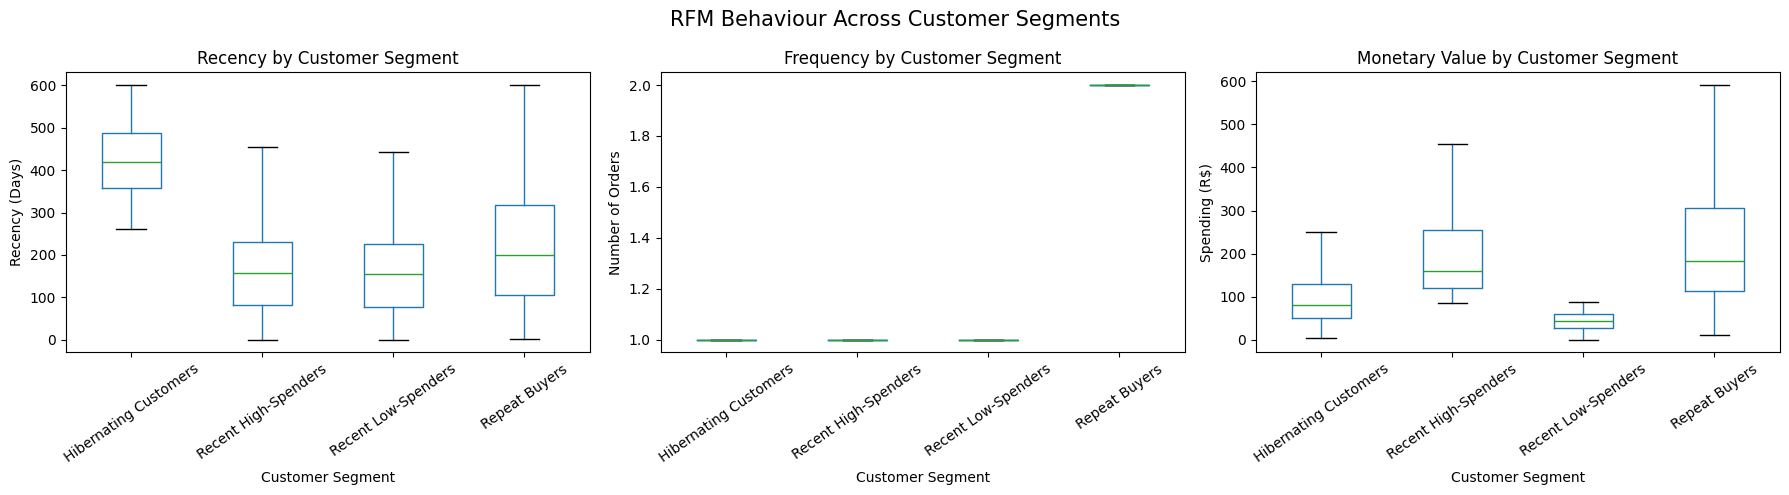

In [ ]:
import matplotlib.pyplot as plt

# Keep a consistent segment order
segment_order = [
    "Recent Low-Spenders",
    "Hibernating Customers",
    "Repeat Buyers",
    "Recent High-Spenders"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Recency comparison
rfm_model.boxplot(
    column="recency",
    by="cluster_name",
    ax=axes[0],
    grid=False,
    showfliers=False
)
axes[0].set_title("Recency by Customer Segment")
axes[0].set_xlabel("Customer Segment")
axes[0].set_ylabel("Recency (Days)")
axes[0].tick_params(axis="x", rotation=35)

# Frequency comparison
rfm_model.boxplot(
    column="frequency",
    by="cluster_name",
    ax=axes[1],
    grid=False,
    showfliers=False
)
axes[1].set_title("Frequency by Customer Segment")
axes[1].set_xlabel("Customer Segment")
axes[1].set_ylabel("Number of Orders")
axes[1].tick_params(axis="x", rotation=35)

# Monetary comparison
rfm_model.boxplot(
    column="monetary",
    by="cluster_name",
    ax=axes[2],
    grid=False,
    showfliers=False
)
axes[2].set_title("Monetary Value by Customer Segment")
axes[2].set_xlabel("Customer Segment")
axes[2].set_ylabel("Spending (R$)")
axes[2].tick_params(axis="x", rotation=35)

plt.suptitle("RFM Behaviour Across Customer Segments", fontsize=15)
plt.tight_layout()
plt.show()

In [ ]:
# Numerical comparison of RFM behaviour across segments

segment_comparison = rfm_model.groupby("cluster_name").agg(
    customer_count=("customer_unique_id", "count"),

    recency_median=("recency", "median"),
    recency_mean=("recency", "mean"),

    frequency_median=("frequency", "median"),
    frequency_mean=("frequency", "mean"),

    monetary_median=("monetary", "median"),
    monetary_mean=("monetary", "mean")
).round(2)

display(segment_comparison)

,customer_count,recency_median,recency_mean,frequency_median,frequency_mean,monetary_median,monetary_mean
cluster_name,,,,,,,
Hibernating Customers,27189,419.00,425.64,1.00,1.00,82.00,109.90
Recent High-Spenders,32369,157.00,160.73,1.00,1.00,159.00,251.13
Recent Low-Spenders,30999,155.00,154.18,1.00,1.00,43.50,44.40
Repeat Buyers,2801,199.00,219.81,2.00,2.11,182.10,260.05


### 6.3 Revenue contribution by segment

In [ ]:
# Calculate revenue contribution by customer segment

revenue_summary = rfm_model.groupby("cluster_name").agg(
    customer_count=("customer_unique_id", "count"),
    total_revenue=("monetary", "sum"),
    average_spending=("monetary", "mean")
).round(2)

revenue_summary["revenue_percentage"] = (
    revenue_summary["total_revenue"]
    / revenue_summary["total_revenue"].sum() * 100
).round(2)

revenue_summary = revenue_summary.sort_values(
    by="total_revenue",
    ascending=False
)

display(revenue_summary)

print(
    "Total customer revenue: R$",
    round(rfm_model["monetary"].sum(), 2)
)

,customer_count,total_revenue,average_spending,revenue_percentage
cluster_name,,,,
Recent High-Spenders,32369,8128784.92,251.13,61.48
Hibernating Customers,27189,2988101.65,109.90,22.60
Recent Low-Spenders,30999,1376202.79,44.40,10.41
Repeat Buyers,2801,728408.75,260.05,5.51


Total customer revenue: R$ 13221498.11


#### Findings: Segment profiles and revenue

| Segment | Customers | Share | Median recency (days) | Avg orders | Avg spend (R$) | Revenue share |
|---|---:|---:|---:|---:|---:|---:|
| Recent High-Spenders | 32,369 | 34.67% | 157 | 1.00 | 251.13 | 61.48% |
| Recent Low-Spenders | 30,999 | 33.20% | 155 | 1.00 | 44.40 | 10.41% |
| Hibernating Customers | 27,189 | 29.12% | 419 | 1.00 | 109.90 | 22.60% |
| Repeat Buyers | 2,801 | 3.00% | 199 | 2.11 | 260.05 | 5.51% |

## 7. Model Evaluation

In [ ]:
from sklearn.metrics import silhouette_score

# Calculate silhouette score on the full dataset
full_silhouette = silhouette_score(
    X_scaled,
    rfm_model["cluster"]
)

print("Full Dataset Silhouette Score:", round(full_silhouette, 4))

Full Dataset Silhouette Score: 0.3685


#### Findings: Model quality
The full-data silhouette score is **0.3685**, consistent with the 0.3694 measured on the sample for K = 4. This indicates moderate cluster separation, which is expected when 97% of customers share the same purchase frequency and the segments are driven mainly by recency and spend.

## 8. Export Results
`olist_customer_segments.csv` is the input for Notebook 05.

In [ ]:
# Prepare final customer segmentation dataset

final_customer_segments = rfm_model[
    [
        "customer_unique_id",
        "recency",
        "frequency",
        "monetary",
        "cluster",
        "cluster_name"
    ]
].copy()

# Export as CSV
final_customer_segments.to_csv(
    "olist_customer_segments.csv",
    index=False
)

print("Export completed!")
print("Total customers:", len(final_customer_segments))
print("Total columns:", len(final_customer_segments.columns))

display(final_customer_segments.head())

Export completed!
Total customers: 93358
Total columns: 6


,customer_unique_id,recency,frequency,monetary,cluster,cluster_name
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,129.90,3,Recent High-Spenders
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,18.90,0,Recent Low-Spenders
2,0000f46a3911fa3c0805444483337064,537,1,69.00,1,Hibernating Customers
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,0,Recent Low-Spenders
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,3,Recent High-Spenders


In [ ]:
# Export all analytical summary tables

cluster_profile.to_csv(
    "olist_cluster_profiles.csv"
)

segment_comparison.to_csv(
    "olist_segment_comparison.csv"
)

revenue_summary.to_csv(
    "olist_segment_revenue_summary.csv"
)

segment_summary.to_csv(
    "olist_segment_customer_summary.csv",
    index=False
)

print("All summary files exported successfully!")
print("1. olist_cluster_profiles.csv")
print("2. olist_segment_comparison.csv")
print("3. olist_segment_revenue_summary.csv")
print("4. olist_segment_customer_summary.csv")

All summary files exported successfully!
1. olist_cluster_profiles.csv
2. olist_segment_comparison.csv
3. olist_segment_revenue_summary.csv
4. olist_segment_customer_summary.csv
